# N-BEATS and Temporal Fusion Transformer

We evaluate N-BEATS and TFT using the same four chronological
cross-validation folds and 28-day forecast horizon as our earlier models.

All preprocessing and training decisions use data available at the
forecast origin. Inner validation controls training duration.
The final test period remains excluded from model development.

We use the NeuralForecast implementations and record package versions
to support reproducibility.

In [1]:
%pip install neuralforecast
%pip show neuralforecast lightning lightning-fabric pytorch-lightning torch


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Name: neuralforecast
Version: 3.3.0
Summary: Time series forecasting suite using deep learning models
Home-page: https://github.com/Nixtla/neuralforecast/
Author: 
Author-email: Nixtla <business@nixtla.io>
License: Apache-2.0
Location: c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages
Requires: coreforecast, fsspec, numpy, optuna, pandas, pytorch-lightning, ray, safetensors, scipy, torch, tornado, utilsforecast
Required-by: 
---
Name: pytorch-lightning
Version: 2.6.6
Summary: PyTorch Lightning is the lightweight PyTorch wrapper for ML researchers. Scale your models. Write less boilerplate.
Home-page: https://github.com/Lightning-AI/lightning
Author: Lightning AI et al.
Author-email: developer@lightning.ai
License: Apache-2.0
Location: c:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages
Requires: fsspec, lightning-utilities, packaging, PyYAML, torch, torchmetrics, tqdm, typing-extensions
Required-by: neuralforecast
---
Name: torch
Version: 2.9

In [2]:
import sys
import inspect
from importlib.metadata import version

import torch
from neuralforecast import NeuralForecast
from neuralforecast.models import NBEATS, TFT
from neuralforecast.losses.pytorch import MSE

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("NeuralForecast:", version("neuralforecast"))
print("PyTorch Lightning:", version("pytorch-lightning"))
print("CUDA available:", torch.cuda.is_available())

print("\nNBEATS constructor:")
print(inspect.signature(NBEATS.__init__))

print("\nTFT constructor:")
print(inspect.signature(TFT.__init__))

Python: 3.12.5
PyTorch: 2.9.1+cpu
NeuralForecast: 3.3.0
PyTorch Lightning: 2.6.6
CUDA available: False

NBEATS constructor:
(self, h, input_size, n_harmonics: int = 2, n_polynomials: Optional[int] = None, n_basis: int = 2, basis: str = 'polynomial', stack_types: list = ['identity', 'trend', 'seasonality'], n_blocks: list = [1, 1, 1], mlp_units: list = [[512, 512], [512, 512], [512, 512]], dropout_prob_theta: float = 0.0, activation: str = 'ReLU', shared_weights: bool = False, loss=MAE(), valid_loss=None, max_steps: int = 1000, learning_rate: float = 0.001, num_lr_decays: int = 3, early_stop_patience_steps: int = -1, val_monitor: str = 'ptl/val_loss', val_check_steps: int = 100, batch_size: int = 32, valid_batch_size: Optional[int] = None, windows_batch_size: int = 1024, inference_windows_batch_size: int = -1, start_padding_enabled=False, training_data_availability_threshold=0.0, step_size: int = 1, scaler_type: str = 'identity', random_seed: int = 1, drop_last_loader: bool = False, ali

## 1. Development Data and Evaluation Schedule

We use daily recorded sales totals for the same four stores.
The development data ends on 29 August 2024; the final test period
is excluded.

We preserve missing observations during data preparation.
Missing sales are not interpreted as zero sales.

N-BEATS uses historical target values. TFT additionally receives
calendar variables known at the forecast origin and static store
indicators. Both models forecast the complete next 28 days without
updates from observed validation targets.

In [3]:
from pathlib import Path
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
HORIZON = 28
LOOKBACK = 28

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))

working_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [working_dir, *working_dir.parents]
        if (
            path / "data" / "processed"
            / "retail_forecasting_config.json"
        ).exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Run this notebook from inside the project repository."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results" / "nbeats_tft"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with open(
    PROCESSED_DIR / "retail_forecasting_config.json",
    encoding="utf-8",
) as file:
    config = json.load(file)

TEST_START = pd.Timestamp(config["test_start"])

daily = pd.read_csv(
    PROCESSED_DIR / "retail_daily_store_dev.csv",
    parse_dates=["date"],
)

cv_schedule = pd.read_csv(
    PROCESSED_DIR / "retail_cv_schedule.csv",
    parse_dates=[
        "train_end", "validation_start", "validation_end"
    ],
)

assert not daily.duplicated(["store_id", "date"]).any()
assert daily["date"].max() < TEST_START
assert (cv_schedule["validation_end"] < TEST_START).all()
assert (cv_schedule["horizon_days"] == HORIZON).all()

STORE_IDS = sorted(daily["store_id"].unique())

store_series = {
    store_id: (
        daily.loc[daily["store_id"] == store_id]
        .set_index("date")["y"]
        .sort_index()
        .asfreq("D")
    )
    for store_id in STORE_IDS
}

# NeuralForecast panel format.
panel_parts = []

for store_id, series in store_series.items():
    panel_parts.append(
        pd.DataFrame({
            "unique_id": f"store_{store_id}",
            "ds": series.index,
            "y": series.to_numpy(dtype=float),
        })
    )

nf_dev_raw = (
    pd.concat(panel_parts, ignore_index=True)
    .sort_values(["unique_id", "ds"])
    .reset_index(drop=True)
)

assert not np.isinf(nf_dev_raw["y"]).any()


def add_calendar_features(frame):
    frame = frame.copy()
    dates = pd.DatetimeIndex(frame["ds"])

    # Fixed encodings require no fitting on future observations.
    for day in range(7):
        frame[f"dow_{day}"] = (
            dates.dayofweek == day
        ).astype(np.float32)

    frame["month_start_3d"] = (
        dates.day <= 3
    ).astype(np.float32)

    frame["month_end_3d"] = (
        dates.day >= dates.days_in_month - 2
    ).astype(np.float32)

    return frame


FUTR_EXOG = [
    *[f"dow_{day}" for day in range(7)],
    "month_start_3d",
    "month_end_3d",
]

nf_dev_raw = add_calendar_features(nf_dev_raw)

# Store identity as static one-hot indicators.
static_df = pd.DataFrame({
    "unique_id": [f"store_{sid}" for sid in STORE_IDS]
})

STATIC_EXOG = []

for sid in STORE_IDS:
    column = f"is_store_{sid}"
    static_df[column] = (
        static_df["unique_id"] == f"store_{sid}"
    ).astype(np.float32)
    STATIC_EXOG.append(column)

display(cv_schedule)
display(static_df)
display(nf_dev_raw.head())

,fold,train_end,validation_start,validation_end,horizon_days
0,1,2024-05-09,2024-05-10,2024-06-06,28
1,2,2024-06-06,2024-06-07,2024-07-04,28
2,3,2024-07-04,2024-07-05,2024-08-01,28
3,4,2024-08-01,2024-08-02,2024-08-29,28


,unique_id,is_store_1,is_store_2,is_store_3,is_store_4
0,store_1,1.0,0.0,0.0,0.0
1,store_2,0.0,1.0,0.0,0.0
2,store_3,0.0,0.0,1.0,0.0
3,store_4,0.0,0.0,0.0,1.0


,unique_id,ds,y,dow_0,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6,month_start_3d,month_end_3d
0,store_1,2022-08-28,2922936.17,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,store_1,2022-08-29,3004918.15,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,store_1,2022-08-30,2902352.46,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,store_1,2022-08-31,3533597.63,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,store_1,2022-09-01,4975560.06,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [4]:
audit_rows = []

for fold in cv_schedule.itertuples(index=False):
    outer_origin = pd.Timestamp(fold.train_end)
    inner_origin = outer_origin - pd.Timedelta(days=HORIZON)

    outer_dates = pd.date_range(
        fold.validation_start,
        fold.validation_end,
        freq="D",
    )
    inner_dates = pd.date_range(
        inner_origin + pd.Timedelta(days=1),
        outer_origin,
        freq="D",
    )

    assert len(inner_dates) == len(outer_dates) == HORIZON
    assert outer_dates[0] == (
        outer_origin + pd.Timedelta(days=1)
    )
    assert outer_dates[-1] < TEST_START

    for store_id, series in store_series.items():
        inner_train = series.loc[:inner_origin]
        outer_train = series.loc[:outer_origin]

        assert len(inner_train) >= LOOKBACK + HORIZON

        for origin in [inner_origin, outer_origin]:
            context_dates = pd.date_range(
                end=origin,
                periods=LOOKBACK,
                freq="D",
            )
            assert np.isfinite(
                series.reindex(context_dates).to_numpy()
            ).all(), (
                f"Missing forecast context: store={store_id}, "
                f"origin={origin}"
            )

        assert np.isfinite(
            series.reindex(inner_dates).to_numpy()
        ).all()

        assert np.isfinite(
            series.reindex(outer_dates).to_numpy()
        ).all()

        audit_rows.append({
            "fold": fold.fold,
            "store_id": store_id,
            "inner_origin": inner_origin,
            "outer_origin": outer_origin,
            "inner_train_days": len(inner_train),
            "outer_train_days": len(outer_train),
            "inner_train_missing": int(inner_train.isna().sum()),
            "outer_train_missing": int(outer_train.isna().sum()),
            "inner_validation_days": len(inner_dates),
            "outer_validation_days": len(outer_dates),
        })

nf_data_audit = pd.DataFrame(audit_rows)

display(nf_data_audit)

nf_data_audit.to_csv(
    RESULTS_DIR / "data_boundary_audit.csv",
    index=False,
)

print("All temporal and validation-availability checks passed.")

,fold,store_id,inner_origin,outer_origin,inner_train_days,outer_train_days,inner_train_missing,outer_train_missing,inner_validation_days,outer_validation_days
0,1,1,2024-04-11,2024-05-09,593,621,0,0,28,28
1,1,2,2024-04-11,2024-05-09,593,621,0,0,28,28
2,1,3,2024-04-11,2024-05-09,593,621,1,1,28,28
3,1,4,2024-04-11,2024-05-09,121,149,0,0,28,28
4,2,1,2024-05-09,2024-06-06,621,649,0,0,28,28
5,2,2,2024-05-09,2024-06-06,621,649,0,0,28,28
6,2,3,2024-05-09,2024-06-06,621,649,1,1,28,28
7,2,4,2024-05-09,2024-06-06,149,177,0,0,28,28
8,3,1,2024-06-06,2024-07-04,649,677,0,0,28,28
9,3,2,2024-06-06,2024-07-04,649,677,0,0,28,28


All temporal and validation-availability checks passed.


## 2. N-BEATS Training Protocol

We compare compact generic and interpretable N-BEATS configurations.
For each configuration and outer fold, we select either 100 or 300
optimization steps using mean store-level WAPE on the inner 28-day
validation period. We then initialize a new model and train it on the
complete outer training interval for the selected number of steps.

We scale each store by its mean positive observed training sales.
Inner and outer fits estimate their scales separately using only their
respective training intervals.

The single missing historical observation is filled using the median
of up to eight earlier observed values from the same weekday.
Validation targets remain unchanged. This differs from the earlier
CNN/RNN/LSTM experiment, which excluded windows containing missing data.

N-BEATS uses historical sales only. We evaluate the complete 28-day
forecast without updating it with validation observations.

### Extended Training-Budget Search

Both N-BEATS configurations selected 300 optimization steps on every
inner-validation period, reaching the upper boundary of our initial
search. We therefore extend the candidate budgets to 100, 300, 600,
and 1000 steps.

We select the budget using inner-validation WAPE and refit a new model
on the complete outer training interval. The final test period remains
excluded. This extension is an adaptive development decision, which
we document when interpreting the cross-validation results.

In [5]:
from time import perf_counter

STEP_BUDGETS = [100, 300, 600, 1000]
NBEATS_VARIANTS = ["generic", "interpretable"]


def prepare_nf_train(cutoff):
    """Causal imputation and training-only scaling."""
    parts = []
    scales = {}

    for store_id, series in store_series.items():
        raw = series.loc[:cutoff].copy()
        positive = raw.loc[raw.notna() & (raw > 0)]
        scale = float(positive.mean())

        assert np.isfinite(scale) and scale > 0
        scales[f"store_{store_id}"] = scale

        filled = raw.copy()

        for date in raw.index[raw.isna()]:
            # Use observed earlier values, not previously imputed values.
            earlier = raw.loc[raw.index < date].dropna()
            same_weekday = earlier.loc[
                earlier.index.dayofweek == date.dayofweek
            ].tail(8)

            if len(same_weekday):
                filled.loc[date] = same_weekday.median()
            elif len(earlier):
                filled.loc[date] = earlier.iloc[-1]
            else:
                raise ValueError(f"No past data for {store_id}, {date}")

        assert np.isfinite(filled.to_numpy()).all()

        parts.append(pd.DataFrame({
            "unique_id": f"store_{store_id}",
            "ds": filled.index,
            "y": filled.to_numpy() / scale,
        }))

    return pd.concat(parts, ignore_index=True), scales


def make_nbeats(variant, steps, seed):
    if variant == "generic":
        stacks = ["identity", "identity"]
    elif variant == "interpretable":
        stacks = ["trend", "seasonality"]
    else:
        raise ValueError(variant)

    return NBEATS(
        h=HORIZON,
        input_size=LOOKBACK,
        stack_types=stacks,
        n_blocks=[1, 1],
        mlp_units=[[64, 64], [64, 64]],
        n_basis=2,
        n_harmonics=2,
        loss=MSE(),
        max_steps=int(steps),
        learning_rate=1e-3,
        num_lr_decays=0,
        early_stop_patience_steps=-1,
        batch_size=len(STORE_IDS),
        windows_batch_size=128,
        inference_windows_batch_size=128,
        start_padding_enabled=False,
        scaler_type="identity",
        random_seed=seed,
        alias="forecast",
        accelerator="cpu",
        devices=1,
        logger=False,
        enable_checkpointing=False,
        enable_progress_bar=False,
        enable_model_summary=False,
        num_sanity_val_steps=0,
        dataloader_kwargs={"num_workers": 0},
    )


def fit_predict_nbeats(variant, steps, origin, seed):
    train_df, scales = prepare_nf_train(origin)

    nf = NeuralForecast(
        models=[make_nbeats(variant, steps, seed)],
        freq="D",
    )
    nf.fit(df=train_df, val_size=0)

    predictions = nf.predict().reset_index(drop=True)

    assert {"unique_id", "ds", "forecast"} <= set(predictions.columns)

    predictions["prediction"] = (
        predictions["forecast"]
        * predictions["unique_id"].map(scales)
    )

    expected_dates = pd.date_range(
        pd.Timestamp(origin) + pd.Timedelta(days=1),
        periods=HORIZON,
        freq="D",
    )

    rows = []

    for store_id in STORE_IDS:
        uid = f"store_{store_id}"
        part = (
            predictions.loc[predictions["unique_id"] == uid]
            .sort_values("ds")
        )

        assert pd.DatetimeIndex(part["ds"]).equals(expected_dates)

        actual = store_series[store_id].reindex(
            expected_dates
        ).to_numpy(dtype=float)

        predicted = part["prediction"].to_numpy(dtype=float)

        assert np.isfinite(actual).all()
        assert np.isfinite(predicted).all()
        assert np.abs(actual).sum() > 0

        rows.append(pd.DataFrame({
            "store_id": store_id,
            "date": expected_dates,
            "actual": actual,
            "prediction": predicted,
        }))

    return nf, pd.concat(rows, ignore_index=True)


def score_nf_predictions(predictions):
    rows = []

    for store_id, part in predictions.groupby("store_id"):
        actual = part["actual"].to_numpy()
        error = part["prediction"].to_numpy() - actual
        denominator = np.abs(actual).sum()

        rows.append({
            "store_id": store_id,
            "MAE": np.abs(error).mean(),
            "RMSE": np.sqrt(np.mean(error ** 2)),
            "WAPE_pct": 100 * np.abs(error).sum() / denominator,
            "bias_pct": 100 * error.sum() / denominator,
        })

    return pd.DataFrame(rows)

In [6]:
nbeats_score_parts = []
nbeats_prediction_parts = []
nbeats_inner_rows = []
nbeats_selection_rows = []

for variant in NBEATS_VARIANTS:
    model_name = f"NBEATS {variant}"

    for fold in cv_schedule.itertuples(index=False):
        started = perf_counter()

        outer_origin = pd.Timestamp(fold.train_end)
        inner_origin = outer_origin - pd.Timedelta(days=HORIZON)
        seed = SEED + int(fold.fold)

        print(f"\n{model_name} | Fold {fold.fold}", flush=True)

        inner_results = []

        for steps in STEP_BUDGETS:
            inner_nf, inner_predictions = fit_predict_nbeats(
                variant, steps, inner_origin, seed
            )

            assert inner_predictions["date"].max() == outer_origin

            inner_wape = float(
                score_nf_predictions(inner_predictions)["WAPE_pct"].mean()
            )

            inner_results.append((inner_wape, steps))

            nbeats_inner_rows.append({
                "model": model_name,
                "fold": fold.fold,
                "steps": steps,
                "inner_WAPE_pct": inner_wape,
            })

            print(
                f"  Inner: steps={steps}, WAPE={inner_wape:.3f}%",
                flush=True,
            )
            del inner_nf

        # Prefer the smaller budget if errors are exactly equal.
        best_inner_wape, selected_steps = min(inner_results)

        outer_nf, outer_predictions = fit_predict_nbeats(
            variant, selected_steps, outer_origin, seed
        )

        assert outer_predictions["date"].min() == pd.Timestamp(
            fold.validation_start
        )
        assert outer_predictions["date"].max() == pd.Timestamp(
            fold.validation_end
        )
        assert (outer_predictions["date"] < TEST_START).all()

        scores = score_nf_predictions(outer_predictions)
        scores["model"] = model_name
        scores["fold"] = fold.fold

        outer_predictions["model"] = model_name
        outer_predictions["fold"] = fold.fold
        outer_predictions["horizon_step"] = (
            outer_predictions["date"] - outer_origin
        ).dt.days

        nbeats_score_parts.append(scores)
        nbeats_prediction_parts.append(outer_predictions)

        nbeats_selection_rows.append({
            "model": model_name,
            "fold": fold.fold,
            "selected_steps": selected_steps,
            "best_inner_WAPE_pct": best_inner_wape,
            "seconds": perf_counter() - started,
        })

        # Save each fitted outer model and progress after every fold.
        outer_nf.save(
            path=str(
                RESULTS_DIR / f"nbeats_{variant}_fold_{fold.fold}"
            ),
            overwrite=True,
            save_dataset=False,
        )

        pd.concat(nbeats_score_parts, ignore_index=True).to_csv(
            RESULTS_DIR / "nbeats_cv_scores.csv", index=False
        )
        pd.concat(nbeats_prediction_parts, ignore_index=True).to_csv(
            RESULTS_DIR / "nbeats_cv_predictions.csv", index=False
        )
        pd.DataFrame(nbeats_inner_rows).to_csv(
            RESULTS_DIR / "nbeats_inner_search.csv", index=False
        )
        pd.DataFrame(nbeats_selection_rows).to_csv(
            RESULTS_DIR / "nbeats_step_selection.csv", index=False
        )

        print(
            f"  Selected {selected_steps} steps; "
            f"outer WAPE={scores['WAPE_pct'].mean():.3f}%",
            flush=True,
        )

        del outer_nf

nbeats_scores = pd.concat(nbeats_score_parts, ignore_index=True)
nbeats_predictions = pd.concat(
    nbeats_prediction_parts, ignore_index=True
)

assert not nbeats_scores.duplicated(
    ["model", "fold", "store_id"]
).any()

nbeats_summary = (
    nbeats_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "size"),
    )
    .sort_values("mean_WAPE_pct")
)

assert (nbeats_summary["evaluated_store_folds"] == 16).all()

nbeats_summary.to_csv(RESULTS_DIR / "nbeats_cv_summary.csv")

display(nbeats_summary)
display(pd.DataFrame(nbeats_selection_rows))


NBEATS generic | Fold 1


Seed set to 43
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
`Trainer.fit` stopped: `max_steps=100` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores


  Inner: steps=100, WAPE=13.329%


Seed set to 43
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
`Trainer.fit` stopped: `max_steps=300` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores


  Inner: steps=300, WAPE=12.382%


Seed set to 43
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
`Trainer.fit` stopped: `max_steps=600` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores


... (73 outputs left out)

Seed set to 46
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
`Trainer.fit` stopped: `max_steps=600` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores


  Selected 600 steps; outer WAPE=5.189%


,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds
model,,,,
NBEATS interpretable,8.920472,28.129955,-2.212050,16
NBEATS generic,9.055836,26.280453,-0.449354,16


,model,fold,selected_steps,best_inner_WAPE_pct,seconds
0,NBEATS generic,1,1000,11.590281,33.454262
1,NBEATS generic,2,300,15.769190,22.512002
2,NBEATS generic,3,1000,6.750470,29.012121
3,NBEATS generic,4,600,5.125173,25.699514
4,NBEATS interpretable,1,1000,11.269459,44.923082
5,NBEATS interpretable,2,300,15.120559,35.041224
6,NBEATS interpretable,3,300,7.157303,29.065615
7,NBEATS interpretable,4,600,5.143339,27.710169


## 3. Temporal Fusion Transformer

We compare TFT models with hidden sizes 16 and 32, two attention heads,
and dropout 0.1. The models use historical sales, static store indicators,
and calendar features known for the complete forecast horizon.

For each configuration and fold, we select the training budget from
100, 300, 600, and 1000 optimization steps using mean store-level
inner-validation WAPE. A newly initialized model is then fitted on
the complete outer training interval.

We retain the training-only scaling and causal imputation used for
N-BEATS. We use MSE for training and evaluate point forecasts with
the same outer-validation metrics as our earlier models.

In [7]:
TFT_WIDTHS = [16, 32]
TFT_STEP_BUDGETS = [100, 300, 600, 1000]


def make_tft(width, steps, seed):
    return TFT(
        h=HORIZON,
        input_size=LOOKBACK,
        stat_exog_list=STATIC_EXOG,
        futr_exog_list=FUTR_EXOG,
        hidden_size=width,
        n_head=2,
        dropout=0.1,
        attn_dropout=0.0,
        loss=MSE(),
        max_steps=int(steps),
        learning_rate=1e-3,
        num_lr_decays=-1,
        early_stop_patience_steps=-1,
        batch_size=len(STORE_IDS),
        windows_batch_size=64,
        inference_windows_batch_size=64,
        start_padding_enabled=False,
        scaler_type="identity",
        random_seed=seed,
        alias="forecast",
        accelerator="cpu",
        devices=1,
        logger=False,
        enable_checkpointing=False,
        enable_progress_bar=False,
        enable_model_summary=False,
        num_sanity_val_steps=0,
        gradient_clip_val=1.0,
        dataloader_kwargs={"num_workers": 0},
    )


def fit_predict_tft(width, steps, origin, seed):
    train_df, scales = prepare_nf_train(origin)
    train_df = add_calendar_features(train_df)

    dates = pd.date_range(
        pd.Timestamp(origin) + pd.Timedelta(days=1),
        periods=HORIZON,
        freq="D",
    )

    # Future inputs contain calendar features only, without target values.
    future_df = pd.concat(
        [
            pd.DataFrame({
                "unique_id": f"store_{sid}",
                "ds": dates,
            })
            for sid in STORE_IDS
        ],
        ignore_index=True,
    )
    future_df = add_calendar_features(future_df)

    nf = NeuralForecast(
        models=[make_tft(width, steps, seed)],
        freq="D",
    )

    nf.fit(
        df=train_df,
        static_df=static_df,
        val_size=0,
    )

    predictions = nf.predict(
        futr_df=future_df
    ).reset_index(drop=True)

    predictions["prediction"] = (
        predictions["forecast"]
        * predictions["unique_id"].map(scales)
    )

    rows = []

    for store_id in STORE_IDS:
        part = (
            predictions.loc[
                predictions["unique_id"] == f"store_{store_id}"
            ]
            .sort_values("ds")
        )

        assert pd.DatetimeIndex(part["ds"]).equals(dates)

        actual = store_series[store_id].reindex(
            dates
        ).to_numpy(dtype=float)

        predicted = part["prediction"].to_numpy(dtype=float)

        assert np.isfinite(actual).all()
        assert np.isfinite(predicted).all()
        assert np.abs(actual).sum() > 0

        rows.append(pd.DataFrame({
            "store_id": store_id,
            "date": dates,
            "actual": actual,
            "prediction": predicted,
        }))

    return nf, pd.concat(rows, ignore_index=True)

In [8]:
tft_score_parts = []
tft_prediction_parts = []
tft_inner_rows = []
tft_selection_rows = []

for width in TFT_WIDTHS:
    model_name = f"TFT width={width}"

    for fold in cv_schedule.itertuples(index=False):
        started = perf_counter()

        outer_origin = pd.Timestamp(fold.train_end)
        inner_origin = outer_origin - pd.Timedelta(days=HORIZON)
        seed = SEED + int(fold.fold)

        print(f"\n{model_name} | Fold {fold.fold}", flush=True)

        inner_results = []

        for steps in TFT_STEP_BUDGETS:
            inner_nf, inner_predictions = fit_predict_tft(
                width, steps, inner_origin, seed
            )

            assert inner_predictions["date"].max() == outer_origin

            inner_wape = float(
                score_nf_predictions(inner_predictions)["WAPE_pct"].mean()
            )

            inner_results.append((inner_wape, steps))

            tft_inner_rows.append({
                "model": model_name,
                "fold": fold.fold,
                "steps": steps,
                "inner_WAPE_pct": inner_wape,
            })

            print(
                f"  Inner: steps={steps}, WAPE={inner_wape:.3f}%",
                flush=True,
            )

            # Save inner-search progress immediately.
            pd.DataFrame(tft_inner_rows).to_csv(
                RESULTS_DIR / "tft_inner_search.csv",
                index=False,
            )

            del inner_nf

        best_inner_wape, selected_steps = min(inner_results)

        outer_nf, outer_predictions = fit_predict_tft(
            width, selected_steps, outer_origin, seed
        )

        assert outer_predictions["date"].min() == pd.Timestamp(
            fold.validation_start
        )
        assert outer_predictions["date"].max() == pd.Timestamp(
            fold.validation_end
        )
        assert (outer_predictions["date"] < TEST_START).all()

        scores = score_nf_predictions(outer_predictions)
        scores["model"] = model_name
        scores["fold"] = fold.fold

        outer_predictions["model"] = model_name
        outer_predictions["fold"] = fold.fold
        outer_predictions["horizon_step"] = (
            outer_predictions["date"] - outer_origin
        ).dt.days

        tft_score_parts.append(scores)
        tft_prediction_parts.append(outer_predictions)

        tft_selection_rows.append({
            "model": model_name,
            "fold": fold.fold,
            "selected_steps": selected_steps,
            "best_inner_WAPE_pct": best_inner_wape,
            "seconds": perf_counter() - started,
        })

        outer_nf.save(
            path=str(
                RESULTS_DIR / f"tft_w{width}_fold_{fold.fold}"
            ),
            overwrite=True,
            save_dataset=False,
        )

        pd.concat(tft_score_parts, ignore_index=True).to_csv(
            RESULTS_DIR / "tft_cv_scores.csv",
            index=False,
        )
        pd.concat(tft_prediction_parts, ignore_index=True).to_csv(
            RESULTS_DIR / "tft_cv_predictions.csv",
            index=False,
        )
        pd.DataFrame(tft_selection_rows).to_csv(
            RESULTS_DIR / "tft_step_selection.csv",
            index=False,
        )

        print(
            f"  Selected {selected_steps} steps; "
            f"outer WAPE={scores['WAPE_pct'].mean():.3f}%; "
            f"time={perf_counter() - started:.1f}s",
            flush=True,
        )

        del outer_nf

tft_scores = pd.concat(tft_score_parts, ignore_index=True)
tft_predictions = pd.concat(
    tft_prediction_parts, ignore_index=True
)

assert not tft_scores.duplicated(
    ["model", "fold", "store_id"]
).any()

tft_summary = (
    tft_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "size"),
    )
    .sort_values("mean_WAPE_pct")
)

assert (tft_summary["evaluated_store_folds"] == 16).all()

tft_summary.to_csv(RESULTS_DIR / "tft_cv_summary.csv")

display(tft_summary)
display(pd.DataFrame(tft_selection_rows))


TFT width=16 | Fold 1


Seed set to 43


GPU available: False, used: False
TPU available: False, using: 0 TPU cores
`Trainer.fit` stopped: `max_steps=100` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores


  Inner: steps=100, WAPE=17.113%


Seed set to 43
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
`Trainer.fit` stopped: `max_steps=300` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores


  Inner: steps=300, WAPE=13.556%


... (74 outputs left out)

Seed set to 46
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
`Trainer.fit` stopped: `max_steps=300` reached.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores


  Selected 300 steps; outer WAPE=5.229%; time=383.4s


,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds
model,,,,
TFT width=32,8.782383,20.126303,-3.166556,16
TFT width=16,9.000304,17.540713,-3.399029,16


,model,fold,selected_steps,best_inner_WAPE_pct,seconds
0,TFT width=16,1,300,13.556092,463.540645
1,TFT width=16,2,300,10.920476,378.865260
2,TFT width=16,3,300,11.751597,375.838407
3,TFT width=16,4,300,6.835965,375.357187
4,TFT width=32,1,600,13.895125,514.044524
5,TFT width=32,2,300,12.239226,398.359533
6,TFT width=32,3,1000,9.922193,481.777095
7,TFT width=32,4,300,6.361888,383.373921


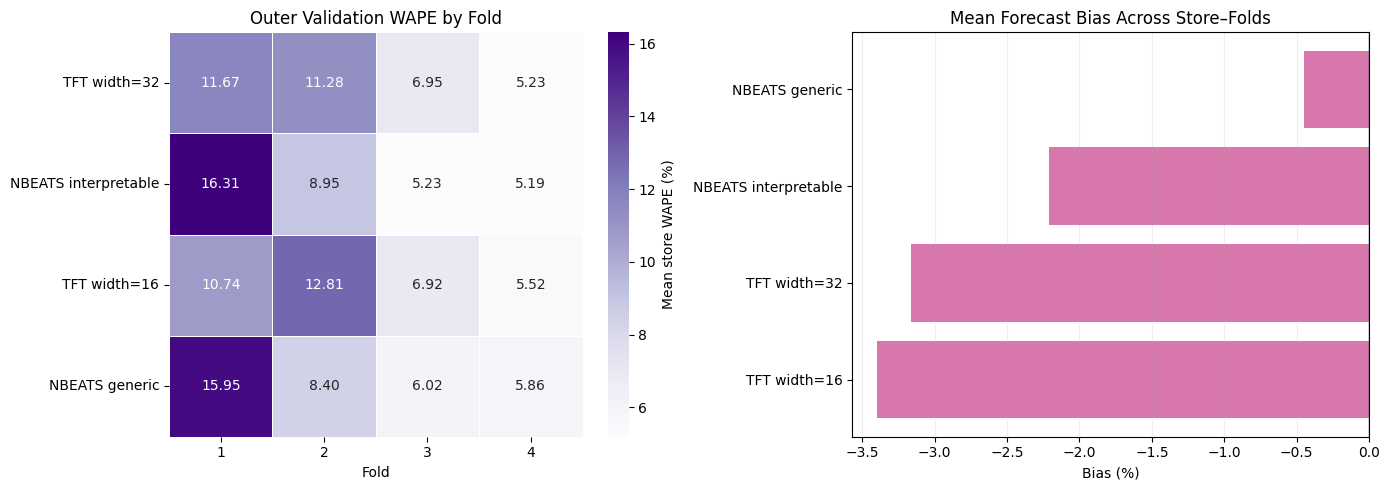

,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds
model,,,,
TFT width=32,8.782,20.126,-3.167,16
NBEATS interpretable,8.920,28.130,-2.212,16
TFT width=16,9.000,17.541,-3.399,16
NBEATS generic,9.056,26.280,-0.449,16


In [9]:
advanced_scores = pd.concat(
    [nbeats_scores, tft_scores],
    ignore_index=True,
)

advanced_summary = (
    advanced_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "size"),
    )
    .sort_values("mean_WAPE_pct")
)

assert not advanced_scores.duplicated(
    ["model", "fold", "store_id"]
).any()
assert (advanced_summary["evaluated_store_folds"] == 16).all()

fold_errors = (
    advanced_scores.groupby(["model", "fold"])["WAPE_pct"]
    .mean()
    .unstack("fold")
    .reindex(advanced_summary.index)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    fold_errors,
    annot=True,
    fmt=".2f",
    cmap="Purples",
    linewidths=0.5,
    cbar_kws={"label": "Mean store WAPE (%)"},
    ax=axes[0],
)
axes[0].set_title("Outer Validation WAPE by Fold")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("")

bias = advanced_summary["mean_bias_pct"].sort_values()
axes[1].barh(
    bias.index,
    bias.values,
    color="#D777AC",
)
axes[1].axvline(0, color="#503366", linewidth=1)
axes[1].set_title("Mean Forecast Bias Across Store–Folds")
axes[1].set_xlabel("Bias (%)")
axes[1].grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

display(advanced_summary.round(3))

advanced_summary.to_csv(
    RESULTS_DIR / "advanced_neural_cv_summary.csv"
)
fold_errors.to_csv(
    RESULTS_DIR / "advanced_neural_fold_errors.csv"
)

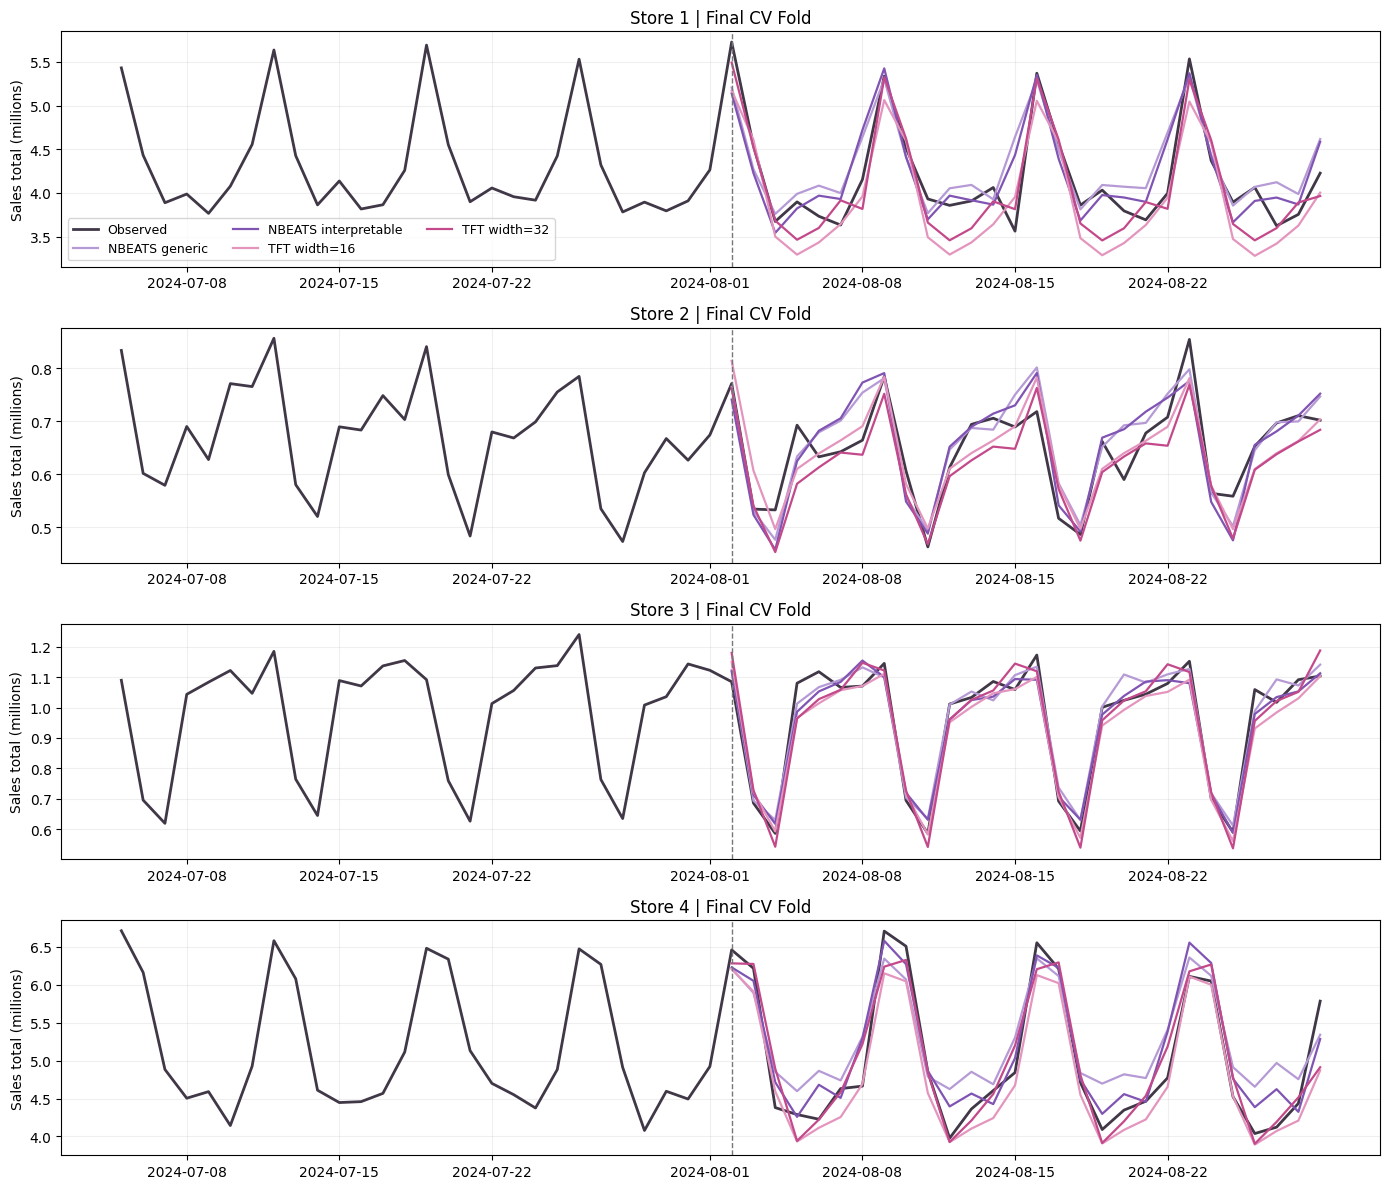

In [10]:
advanced_predictions = pd.concat(
    [nbeats_predictions, tft_predictions],
    ignore_index=True,
)

last_fold = int(cv_schedule["fold"].max())
last_schedule = cv_schedule.loc[
    cv_schedule["fold"] == last_fold
].iloc[0]

plot_colors = {
    "NBEATS generic": "#B59AD5",
    "NBEATS interpretable": "#8054B3",
    "TFT width=16": "#E495BE",
    "TFT width=32": "#C3498B",
}

fig, axes = plt.subplots(
    len(STORE_IDS), 1,
    figsize=(14, 12),
    squeeze=False,
)

for ax, store_id in zip(axes.ravel(), STORE_IDS):
    start = last_schedule["validation_start"] - pd.Timedelta(days=28)
    end = last_schedule["validation_end"]

    observed = store_series[store_id].loc[start:end]

    ax.plot(
        observed.index,
        observed / 1e6,
        color="#403747",
        linewidth=2,
        label="Observed",
    )

    for model_name, color in plot_colors.items():
        part = advanced_predictions.loc[
            (advanced_predictions["model"] == model_name)
            & (advanced_predictions["fold"] == last_fold)
            & (advanced_predictions["store_id"] == store_id)
        ].sort_values("date")

        assert len(part) == HORIZON

        ax.plot(
            part["date"],
            part["prediction"] / 1e6,
            color=color,
            linewidth=1.6,
            label=model_name,
        )

    ax.axvline(
        last_schedule["validation_start"],
        color="#777777",
        linestyle="--",
        linewidth=1,
    )
    ax.set_title(f"Store {store_id} | Final CV Fold")
    ax.set_ylabel("Sales total (millions)")
    ax.grid(alpha=0.2)

axes[0, 0].legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

## 4. Findings and Limitations

TFT with hidden size 32 achieves the lowest mean outer-validation
WAPE among the N-BEATS and TFT configurations (8.782%).
TFT with hidden size 16 has a slightly higher mean error (9.000%)
but a lower worst store–fold error (17.541% versus 20.126%).

Both TFT configurations have negative mean bias, indicating an
average tendency to underpredict recorded sales under our metric.
The preferred configuration therefore depends partly on whether
we prioritize average accuracy or the worst evaluated case.

The extended N-BEATS search illustrates that lower inner-validation
error does not guarantee lower outer-validation error. We retain
the expanded selection protocol rather than choosing between search
versions using their outer scores.

Prophet and Ridge retain lower mean cross-validation WAPE than
these neural configurations. Our results therefore do not support
assuming that greater architectural complexity improves accuracy.

These comparisons use one seed per fold, four stores, and four
validation periods concentrated in late spring and summer.
They compare complete forecasting pipelines, including differences
in available features, rather than isolating architecture alone.
The final test period remains excluded from development.

### Forecast Shape on the Final Validation Fold

All four configurations reproduce the recurring weekly pattern.
For store 1, TFT frequently underpredicts sales between the weekly
peaks. For store 3, the forecasts capture the timing of recurring
declines, although some predicted troughs are deeper than observed.

The forecasts are more regular than the observed series and do not
capture every daily fluctuation. These visual observations concern
the final validation fold and should not be generalized to all periods.